# 0 · What does a link-level simulator tell you?

**NR link-level simulation from zero**, notebook 0 · [All notebooks](README.md) · [Glossary](GLOSSARY.md) · [![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/HelloSYQ/Claude/blob/HEAD/notebooks/learn/00_what_a_link_level_simulator_does.ipynb)

**In one sentence:** a link-level simulator answers *"how fast can a base station send data to one phone, at a given signal quality?"* by imitating, step by step, what the real system does.

**You will learn**
- what a radio *link* is, and what this simulator models;
- decibels, the unit everyone in wireless uses;
- how to run the simulator and read its main result, the spectral-efficiency curve.

**You need** Python and a little numpy; no wireless knowledge. **Time:** about 15 minutes.

**How to use it.** Run the cells from top to bottom with Shift+Enter. The outputs are stored, so you can also just read.

In [1]:
# Setup: make the nrdlsim package importable, then import the basics.
# (On Google Colab this installs nrdlsim from GitHub the first time.)
import os, sys, subprocess, importlib.util
if importlib.util.find_spec("nrdlsim") is None:
    root = os.getcwd()
    while root != os.path.dirname(root) and not os.path.isdir(os.path.join(root, "nrdlsim")):
        root = os.path.dirname(root)
    if os.path.isdir(os.path.join(root, "nrdlsim")):
        sys.path.insert(0, root)              # running inside the repository
    else:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "git+https://github.com/HelloSYQ/Claude"], check=True)

import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
plt.rcParams.update({"figure.dpi": 80, "axes.grid": True, "grid.alpha": 0.3})

def check(question, answer, expected, tol):
    """Say whether an answer is within tol of the expected value."""
    if answer is None:
        print(f"{question}: put your answer in place of None and run the cell again")
    elif abs(answer - expected) <= tol:
        print(f"{question}: yes, {answer} is right")
    else:
        print(f"{question}: not quite, try again (or open the answer below)")

## 1 · The question

When your phone downloads a video, the data comes from a **base station**: the antennas on a mast that serve your area. In 5G the base station is called a *gNB* and the phone a *UE* (user equipment). Data travelling from the base station to the phone is the **downlink**.

The base station sends the data as radio waves. On the way they get weaker, bounce off buildings and arrive as several echoes, and at the phone they are mixed with **noise**, random disturbances that every receiver picks up. The phone has to work out which bits were sent.

One transmitter and one receiver form a **link**. A **link-level simulator** (LLS) models one link in detail: the bits, the coding, the radio waves, the echoes, the noise, the receiver, and the base station's decisions about how fast to send. It answers one question:

> For a given signal quality, how many bits per second arrive correctly?

A *system-level* simulator makes the opposite trade-off: many base stations and phones, each link simplified. Its simplified links are calibrated with link-level results.

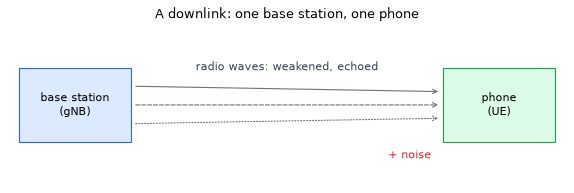

In [2]:
# This cell only draws the picture; you can skip its code.
fig, ax = plt.subplots(figsize=(9, 2.6))
ax.axis("off"); ax.set_xlim(0, 10); ax.set_ylim(0, 3)
ax.add_patch(plt.Rectangle((0.2, 0.8), 2.0, 1.4, fc="#dbeafe", ec="#2563eb"))
ax.text(1.2, 1.5, "base station\n(gNB)", ha="center", va="center")
ax.add_patch(plt.Rectangle((7.8, 0.8), 2.0, 1.4, fc="#dcfce7", ec="#16a34a"))
ax.text(8.8, 1.5, "phone\n(UE)", ha="center", va="center")
for start, end, style in ((1.85, 1.75, "-"), (1.5, 1.5, "--"), (1.15, 1.25, ":")):
    ax.annotate("", xy=(7.75, end), xytext=(2.25, start),
                arrowprops=dict(arrowstyle="->", linestyle=style, color="#6b7280"))
ax.text(5, 2.15, "radio waves: weakened, echoed", ha="center", color="#374151")
ax.text(7.2, 0.5, "+ noise", ha="center", color="#dc2626")
ax.set_title("A downlink: one base station, one phone")
plt.show()

## 2 · Decibels in five minutes

Wireless engineers compare powers as **ratios**, and the ratios span enormous ranges: the signal that reaches a phone can be a billion billion times weaker than what the base station transmits. So ratios are written in **decibels (dB)**:

$$\text{ratio in dB} = 10 \cdot \log_{10}(\text{ratio})$$

A few values are worth remembering:

| ratio | in dB |
|---|---|
| 1 (equal) | 0 dB |
| 2 | about 3 dB |
| 10 | 10 dB |
| 100 | 20 dB |
| 1/10 | −10 dB |

Multiplying ratios means adding decibels: 200 = 2 × 100 is 3 + 20 = 23 dB.

The ratio that matters most here is the **signal-to-noise ratio (SNR)**: the signal power divided by the noise power. An SNR of 20 dB means the signal is 100 times stronger than the noise; at 0 dB they are equally strong; at −5 dB the noise is about three times stronger than the signal, and, as you'll see, data still gets through.

In [3]:
def to_db(ratio):
    return 10 * np.log10(ratio)

def from_db(db):
    return 10 ** (db / 10)

for db in (-10, 0, 3, 6, 10, 20, 30):
    print(f"{db:4d} dB  ->  ratio {from_db(db):8.2f}")
print("\nthe ratio 200 in dB:", round(to_db(200), 1))

 -10 dB  ->  ratio     0.10
   0 dB  ->  ratio     1.00
   3 dB  ->  ratio     2.00
   6 dB  ->  ratio     3.98
  10 dB  ->  ratio    10.00
  20 dB  ->  ratio   100.00
  30 dB  ->  ratio  1000.00

the ratio 200 in dB: 23.0


**Check yourself.** The noise power doubles while the signal stays the same. By how many dB does the SNR drop? Replace `None` with your answer and run the cell.

In [4]:
answer = None
check("SNR drop when the noise doubles (dB)", answer, expected=3, tol=0.1)

SNR drop when the noise doubles (dB): put your answer in place of None and run the cell again


<details><summary>Answer</summary>

About 3 dB. The SNR halves, and a factor of 2 is 10·log₁₀(2) ≈ 3.01 dB.

</details>

## 3 · Run the simulator once

Let's treat the simulator as a black box and look at what comes out. The set-up used throughout this series:

- a **20 MHz** slice of spectrum at **3.5 GHz**, a typical 5G band. It is divided into 51 *resource blocks* (notebook 6);
- a base station with **4 antennas** and a phone with **2**;
- **TDL-C**, a standard 3GPP model of an urban radio channel, with echoes spread over about 100 ns, and the phone carried at walking speed (3 km/h);
- SNRs from −5 dB to 40 dB.

At each SNR the simulator sends data for 400 *slots* of 0.5 ms each, 0.2 s in all. In every slot it goes through all the steps a real system does, and it counts the bits that arrive correctly.

**Predict first:** as the SNR goes up, does the data rate keep growing forever, or does it level off?

In [5]:
from nrdlsim.config import SimConfig, CarrierConfig, PDSCHConfig, AntennaConfig, ChannelConfig
from nrdlsim.link_simulator import NRDownlinkSimulator

config = SimConfig(
    carrier=CarrierConfig(mu=1, n_size_grid=51),          # 30 kHz subcarriers, 51 resource blocks
    pdsch=PDSCHConfig(num_rb=51, num_layers=2, mcs_table=2),  # use all 51 blocks, up to 2 streams
    antenna=AntennaConfig(n_tx=4, n_rx=2),                # 4 antennas at the base station, 2 at the phone
    channel=ChannelConfig(model="TDL-C", delay_spread_ns=100, ue_speed_kmh=3.0),
    snr_db_range=(-5, 40, 2.5),                           # -5 dB to 40 dB in 2.5 dB steps
    num_slots=400)                                        # 400 slots of 0.5 ms per SNR

results = NRDownlinkSimulator(config).run()
snr_db = np.array([r.snr_db for r in results])
se = np.array([r.spectral_efficiency for r in results])
print(f"simulated {len(results)} SNR points")

simulated 19 SNR points


## 4 · Reading the curve

The simulator reports the **spectral efficiency (SE)**: the bits per second carried by each hertz of spectrum, in bit/s/Hz. It is the data rate divided by the bandwidth, so it doesn't depend on how much spectrum you have. Multiply it by the bandwidth to get the data rate: on our 18.4 MHz of occupied spectrum, 1 bit/s/Hz is 18.4 Mbit/s.

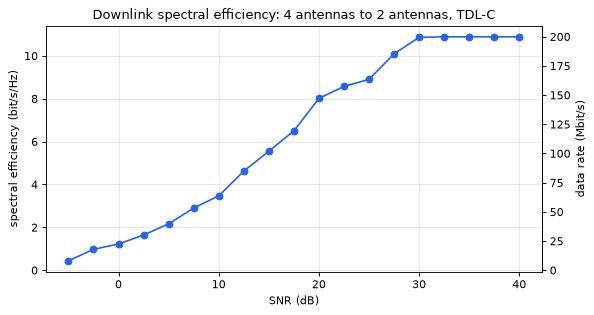

SNR  0 dB:  1.22 bit/s/Hz =   22 Mbit/s
SNR 10 dB:  3.47 bit/s/Hz =   64 Mbit/s
SNR 20 dB:  8.02 bit/s/Hz =  147 Mbit/s
SNR 30 dB: 10.86 bit/s/Hz =  199 Mbit/s
SNR 40 dB: 10.89 bit/s/Hz =  200 Mbit/s


In [6]:
bandwidth_hz = 51 * 12 * 30e3        # 51 resource blocks x 12 subcarriers x 30 kHz

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(snr_db, se, "o-", color="#2563eb")
ax.set_xlabel("SNR (dB)"); ax.set_ylabel("spectral efficiency (bit/s/Hz)")
ax.set_title("Downlink spectral efficiency: 4 antennas to 2 antennas, TDL-C")
right = ax.secondary_yaxis("right", functions=(lambda s: s * bandwidth_hz / 1e6,
                                               lambda r: r * 1e6 / bandwidth_hz))
right.set_ylabel("data rate (Mbit/s)")
plt.show()

for target in (0, 10, 20, 30, 40):
    k = int(np.argmin(np.abs(snr_db - target)))
    print(f"SNR {target:2d} dB: {se[k]:5.2f} bit/s/Hz = {se[k] * bandwidth_hz / 1e6:4.0f} Mbit/s")

**What you see**

1. **Even at −5 dB, data gets through**, slowly. The noise is stronger than the signal, but the base station sends few bits per symbol with plenty of redundancy, and the antennas add gain, so the phone can still decode them (notebooks 2–4 and 7).
2. **More SNR, more data.** A cleaner signal lets the base station pack more bits into each symbol (notebook 2) and send two streams at once to the phone's two antennas (notebook 7).
3. **The curve levels off.** There is a fastest setting, and no amount of SNR goes beyond it. The next cell works out where it is.
4. **The curve isn't perfectly smooth.** Fading is random and each point is only 0.2 s of transmission. More slots make it smoother.

**Where does the top speed come from?** The fastest setting combines the densest constellation in the table (256QAM, 8 bits per symbol, notebook 2), the highest code rate (0.93, so only 7 % redundancy, notebook 3) and two streams (notebook 7). Part of the time and frequency also carries reference signals and control information instead of data (notebook 6).

fastest setting: 256QAM, code rate 0.93, 2 streams
-> at most 100392 bits per slot = 10.94 bit/s/Hz = 201 Mbit/s


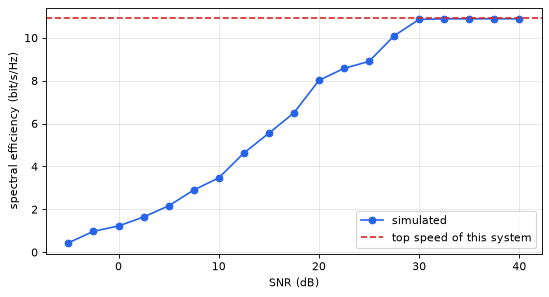

In [7]:
from nrdlsim import mcs_tables, tbs as tbs_mod, resource_grid

top = mcs_tables.get_mcs(mcs_tables.num_mcs(2) - 1, 2)      # the fastest setting in the table
data_res = resource_grid.data_re_per_rb(config.pdsch)        # data-carrying resource elements per block
top_bits = tbs_mod.compute_tbs(data_res, 51, top.modulation_order, top.target_code_rate, 2)
ceiling = top_bits / 0.5e-3 / bandwidth_hz                   # bits per 0.5 ms slot -> bit/s/Hz
print(f"fastest setting: {top.modulation_name}, code rate {top.target_code_rate:.2f}, 2 streams")
print(f"-> at most {top_bits} bits per slot = {ceiling:.2f} bit/s/Hz = "
      f"{ceiling * bandwidth_hz / 1e6:.0f} Mbit/s")

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(snr_db, se, "o-", color="#2563eb", label="simulated")
ax.axhline(ceiling, ls="--", color="#dc2626", label="top speed of this system")
ax.set_xlabel("SNR (dB)"); ax.set_ylabel("spectral efficiency (bit/s/Hz)"); ax.legend()
plt.show()

## 5 · What's inside the box

In every 0.5 ms slot the simulator runs the same chain of steps. In plain words, with the notebook that explains each one:

| Step | What happens | Notebook |
|---|---|---|
| Bits to symbols | groups of bits become points of a *constellation* (arrows) | 1, 2 |
| Error-correcting code | redundancy is added so the phone can repair errors | 3 |
| Choosing the speed | the phone reports how well it hears; the base station picks the bits per symbol and the redundancy | 4 |
| The radio channel | the waves are weakened, echoed and faded on the way | 5 |
| The resource grid (OFDM) | the band is cut into many narrow subcarriers and short symbols; some carry reference signals | 6 |
| Several antennas | beamforming and parallel streams (*layers*) | 7 |
| Receiver and error prediction | the phone undoes the channel; the simulator predicts which blocks fail | 8 |
| The slot loop | feedback, retransmissions, counting the bits that got through | 9 |

Notebook 9 opens the box completely; by then every step will be familiar.

## 6 · Try it yourself

**Predict first:** the phone now has **one** antenna instead of two. What happens to the curve at low SNR, and at high SNR?

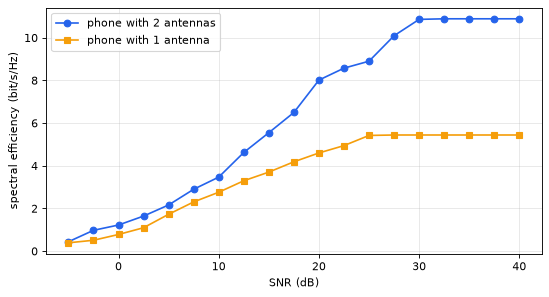

at -5 dB: 0.44 vs 0.39 bit/s/Hz
at 40 dB: 10.89 vs 5.44 bit/s/Hz


In [8]:
config_1rx = SimConfig(
    carrier=CarrierConfig(mu=1, n_size_grid=51),
    pdsch=PDSCHConfig(num_rb=51, num_layers=2, mcs_table=2),
    antenna=AntennaConfig(n_tx=4, n_rx=1),                # the only change: 1 antenna at the phone
    channel=ChannelConfig(model="TDL-C", delay_spread_ns=100, ue_speed_kmh=3.0),
    snr_db_range=(-5, 40, 2.5), num_slots=400)
se_1rx = np.array([r.spectral_efficiency for r in NRDownlinkSimulator(config_1rx).run()])

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(snr_db, se, "o-", color="#2563eb", label="phone with 2 antennas")
ax.plot(snr_db, se_1rx, "s-", color="#f59e0b", label="phone with 1 antenna")
ax.set_xlabel("SNR (dB)"); ax.set_ylabel("spectral efficiency (bit/s/Hz)"); ax.legend()
plt.show()
print(f"at -5 dB: {se[0]:.2f} vs {se_1rx[0]:.2f} bit/s/Hz")
print(f"at {snr_db[-1]:.0f} dB: {se[-1]:.2f} vs {se_1rx[-1]:.2f} bit/s/Hz")

**What happened**

- **At high SNR the top speed halves.** A phone with one antenna can only receive one stream, so the base station sends one stream instead of two (notebook 7).
- **At low SNR the one-antenna phone is slower too.** Two antennas collect twice the signal energy, and they rarely fade at the same moment, so a second antenna also makes a weak signal more usable.

More to try: set `ue_speed_kmh` to 60 (a car), `model` to `"TDL-A"`, or `n_tx` to 8. Predict first, then run.

## Where in the code

- `nrdlsim/config.py`: the configuration objects used above.
- `nrdlsim/link_simulator.py`: `NRDownlinkSimulator`, the slot loop (notebook 9).
- `run_simulation.py`: the same simulation from the command line, for example `python run_simulation.py --plot`.

## Recap

- A **link** is one transmitter and one receiver; a **link-level simulator** models one link in detail.
- **Decibels** turn ratios into sums: +3 dB ≈ ×2, +10 dB = ×10.
- The **SNR** compares the signal power with the noise power.
- The main result is **spectral efficiency vs SNR**. It grows with the SNR and levels off at the system's top speed.

**Words you met:** base station (gNB), phone (UE), downlink, link, noise, decibel, SNR, spectral efficiency, slot. All of them are in the [glossary](GLOSSARY.md).

**Next:** [notebook 1](01_bits_symbols_and_noise.ipynb), how bits become a radio signal and what noise does to it.